# Исследование надёжности заёмщиков

**Учебный проект Яндекс Практикума · Анализ данных на Python**

Кредитный отдел банка хочет понять, как часто у заёмщиков с разным семейным положением и числом детей встречалась задолженность. Я также сравню группы по доходу и цели кредита.

**Что считаю.** В банковской выгрузке `debt = 1` означает, что у клиента была задолженность по возврату кредита. Для каждой группы делю число таких записей на общее число записей группы. Срок и размер задолженности в файле не указаны.

**Что получилось.** После очистки осталось 21 331 наблюдение. Задолженность встречалась в 9,24% записей о заёмщиках с детьми и в 7,54% записей о заёмщиках без детей. Разница составляет 1,70 процентного пункта.

[Знакомство с данными](#overview) · [Предобработка](#preparation) · [Исследование](#analysis) · [Вывод для банка](#conclusion)

<a id="overview"></a>
## Шаг 1. Знакомство с данными

### Задание 1. Загрузить таблицу

В тренажёре источник доступен по пути `/datasets/data.csv`. При локальном запуске можно положить `data.csv` рядом с ноутбуком.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

data_path = Path('/datasets/data.csv')
if not data_path.is_file():
    data_path = Path('data.csv')
data = pd.read_csv(data_path)

### Задание 2. Посмотреть первые 20 строк

При локальном запуске ячейка покажет первые 20 анкет из банковской выгрузки. В публичной версии сохранены групповые результаты.

In [2]:
display(data.head(20))

### Задание 3. Проверить структуру и типы столбцов

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 21525 entries, 0 to 21524
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   children          21525 non-null  int64  
 1   days_employed     19351 non-null  float64
 2   dob_years         21525 non-null  int64  
 3   education         21525 non-null  str    
 4   education_id      21525 non-null  int64  
 5   family_status     21525 non-null  str    
 6   family_status_id  21525 non-null  int64  
 7   gender            21525 non-null  str    
 8   income_type       21525 non-null  str    
 9   debt              21525 non-null  int64  
 10  total_income      19351 non-null  float64
 11  purpose           21525 non-null  str    
dtypes: float64(2), int64(5), str(5)
memory usage: 2.0 MB


В исходной таблице 21 525 строк и 12 столбцов. В ней есть сведения о семье, возрасте и образовании клиента, его занятости, доходе и цели кредита. Число заполненных значений у стажа и дохода меньше, чем у остальных полей. Проверю, относятся ли эти пропуски к одним и тем же записям.

<a id="preparation"></a>
## Шаг 2. Предобработка

### Задание 4. Посчитать пропуски в каждом столбце

In [4]:
display(data.isna().sum())

# Маска по исходным индексам пригодится для проверки результата по доходам.
income_missing = data['total_income'].isna()
experience_missing = data['days_employed'].isna()
print('Пропущены оба значения:', (income_missing & experience_missing).sum())
print('Пропущено только одно:', (income_missing ^ experience_missing).sum())

children               0
days_employed       2174
dob_years              0
education              0
education_id           0
family_status          0
family_status_id       0
gender                 0
income_type            0
debt                   0
total_income        2174
purpose                0
dtype: int64

Пропущены оба значения: 2174
Пропущено только одно: 0


### Задание 5. Восстановить доход по типу занятости

Для пропусков возьму медиану дохода клиентов с тем же типом занятости. Сохраню сводку по исходным известным доходам, чтобы в задании 24 сравнить медиану со средним.

In [5]:
observed_income_stats = data['total_income'].agg(['median', 'mean', 'max'])
income_medians = data.groupby('income_type')['total_income'].transform('median')
data['total_income'] = data['total_income'].fillna(income_medians)

### Задание 6. Исправить знак трудового стажа

In [6]:
print('Отрицательных значений стажа:', data['days_employed'].lt(0).sum())
data['days_employed'] = data['days_employed'].abs()

Отрицательных значений стажа: 15906


### Задание 7. Сравнить медианный стаж по типам занятости

In [7]:
display(data.groupby('income_type')['days_employed'].median().round(2))

income_type
безработный        366413.65
в декрете            3296.76
госслужащий          2689.37
компаньон            1547.38
пенсионер          365213.31
предприниматель       520.85
сотрудник            1574.20
студент               578.75
Name: days_employed, dtype: float64

У пенсионеров и безработных медианный стаж превышает 365 тысяч дней — это около тысячи лет. Смена знака исправила только отрицательные значения. Возможно, часть записей пришла из источника с другой единицей времени. Проверить это по выгрузке нельзя. Сохраняю эти значения по условию проекта. В сравнениях по детям, семейному положению, доходу и цели кредита стаж не используется.

### Задание 8. Найти значения числа детей

In [8]:
display(data['children'].unique())
display(data['children'].value_counts().sort_index().rename('Записей'))

array([ 1,  0,  3,  2, -1,  4, 20,  5])

children
-1        47
 0     14149
 1      4818
 2      2055
 3       330
 4        41
 5         9
 20       76
Name: Записей, dtype: int64

### Задание 9. Исключить два аномальных значения

В 47 строках указано −1, ещё в 76 — 20 детей. Исключу обе группы по условию задания. Например, превращение 20 в 2 приписало бы семье число детей, которое мы не можем проверить.

In [9]:
data = data.loc[~data['children'].isin([-1, 20])].copy()

### Задание 10. Проверить оставшиеся значения

In [10]:
display(data['children'].unique())

array([1, 0, 3, 2, 4, 5])

### Задание 11. Заполнить пропуски в стаже

In [11]:
experience_medians = data.groupby('income_type')['days_employed'].transform('median')
data['days_employed'] = data['days_employed'].fillna(experience_medians)

### Задание 12. Повторно посчитать пропуски

In [12]:
display(data.isna().sum())

children            0
days_employed       0
dob_years           0
education           0
education_id        0
family_status       0
family_status_id    0
gender              0
income_type         0
debt                0
total_income        0
purpose             0
dtype: int64

### Задание 13. Привести ежемесячный доход к целому числу

In [13]:
data['total_income'] = data['total_income'].astype(int)
print(data['total_income'].dtype)

int64


### Задание 14. Привести образование к единому регистру

In [14]:
data['education'] = data['education'].str.lower()
display(data['education'].value_counts())

education
среднее                15136
высшее                  5237
неоконченное высшее      741
начальное                282
ученая степень             6
Name: count, dtype: int64

### Задание 15. Найти и удалить полные дубликаты

In [15]:
duplicate_count = data.duplicated().sum()
print('Полных дубликатов после предобработки:', duplicate_count)
data = data.drop_duplicates().copy()
print('Осталось строк:', len(data))

Полных дубликатов после предобработки: 71
Осталось строк: 21331


После исключения 123 строк с аномальными значениями числа детей и удаления 71 полной повторной строки осталось 21 331 наблюдение. Единицей сравнения дальше служит одна оставшаяся запись. Без идентификатора клиента нельзя проверить, встречается ли один человек в нескольких разных строках.

### Задание 16. Сформировать категории дохода

Границы заданы в рублях в месяц. Верхнее значение каждого диапазона включено в него. Например, доход 200 000 относится к C, а 200 001 — к B.

In [16]:
def categorize_income(income):
    if income < 0:
        raise ValueError('Доход не может быть отрицательным')
    if income <= 30_000:
        return 'E'
    if income <= 50_000:
        return 'D'
    if income <= 200_000:
        return 'C'
    if income <= 1_000_000:
        return 'B'
    return 'A'


data['total_income_category'] = data['total_income'].apply(categorize_income)
display(data['total_income_category'].value_counts().reindex(list('EDCBA')))

total_income_category
E       22
D      349
C    15921
B     5014
A       25
Name: count, dtype: int64

### Задание 17. Посмотреть все формулировки целей

In [17]:
display(data['purpose'].unique())

<StringArray>
[                         'покупка жилья',
                'приобретение автомобиля',
             'дополнительное образование',
                        'сыграть свадьбу',
                      'операции с жильем',
                            'образование',
                  'на проведение свадьбы',
                'покупка жилья для семьи',
                   'покупка недвижимости',
      'покупка коммерческой недвижимости',
             'покупка жилой недвижимости',
 'строительство собственной недвижимости',
                           'недвижимость',
             'строительство недвижимости',
     'на покупку подержанного автомобиля',
           'на покупку своего автомобиля',
  'операции с коммерческой недвижимостью',
       'строительство жилой недвижимости',
                                  'жилье',
        'операции со своей недвижимостью',
                             'автомобили',
                  'заняться образованием',
       'сделка с подержанным автомобилем

### Задание 18. Объединить цели кредита в четыре категории

Выражения «покупка жилья», «ремонт жилью» и «строительство недвижимости» относятся к недвижимости. Общие части слов позволяют объединить их, сохранив исходную формулировку в отдельном столбце.

In [18]:
def categorize_purpose(purpose):
    text = purpose.lower()
    if 'автомоб' in text:
        return 'операции с автомобилем'
    if 'жил' in text or 'недвиж' in text:
        return 'операции с недвижимостью'
    if 'свадьб' in text:
        return 'проведение свадьбы'
    if 'образован' in text:
        return 'получение образования'
    raise ValueError(f'Неизвестная формулировка цели: {purpose}')


data['purpose_category'] = data['purpose'].apply(categorize_purpose)
display(data['purpose_category'].value_counts())
assert data['debt'].isin([0, 1]).all()

purpose_category
операции с недвижимостью    10751
операции с автомобилем       4279
получение образования        3988
проведение свадьбы           2313
Name: count, dtype: int64

<a id="analysis"></a>
## Шаг 3. У каких групп чаще встречалась задолженность

### Задание 19. Имеет ли значение число детей

Показатель `debt` принимает два значения. Сумма единиц даёт число записей с задолженностью, а среднее — их долю. Во всех четырёх сравнениях вывожу и численность группы, и долю. Разницу между двумя долями указываю в процентных пунктах (п. п.).

In [19]:
def debt_summary(frame, column):
    totals = frame.groupby(column)['debt'].agg(['size', 'sum', 'mean'])
    totals.columns = ['Записей', 'С задолженностью', 'Доля, %']
    totals['Доля, %'] = totals['Доля, %'].mul(100)
    return totals


overall_rate = 100 * data['debt'].mean()
children_table = debt_summary(data, 'children')
display(children_table.rename_axis('Детей').round(2))
has_children = data['children'].gt(0).map({False: 'Без детей', True: 'Есть дети'})
display(debt_summary(data.assign(children_group=has_children), 'children_group')
        .rename_axis('Группа').round(2))

,Записей,С задолженностью,"Доля, %"
Детей,,,
0,14091,1063,7.54
1,4808,444,9.23
2,2052,194,9.45
3,330,27,8.18
4,41,4,9.76
5,9,0,0.00


,Записей,С задолженностью,"Доля, %"
Группа,,,
Без детей,14091,1063,7.54
Есть дети,7240,669,9.24


Среди заёмщиков без детей задолженность отмечена в 1 063 из 14 091 записей (7,54%). Среди заёмщиков с детьми — в 669 из 7 240 (9,24%). Разница составляет **1,70 п. п.** Внутри групп рост непоследователен. С двумя детьми доля составляет 9,45%, с тремя — 8,18%. В группе с пятью детьми задолженности не зафиксировано, но в ней всего девять наблюдений.

### Задание 20. Как различаются группы по семейному положению

In [20]:
family_table = debt_summary(data, 'family_status').sort_values('Доля, %', ascending=False)
display(family_table.rename_axis('Семейное положение').round(2))

,Записей,С задолженностью,"Доля, %"
Семейное положение,,,
Не женат / не замужем,2796,273,9.76
гражданский брак,4134,385,9.31
женат / замужем,12261,927,7.56
в разводе,1189,84,7.06
вдовец / вдова,951,63,6.62


Среди состоящих в зарегистрированном браке доля задолженности составляет 7,56% (927 из 12 261). Для гражданского брака она равна 9,31% (385 из 4 134), а у группы «Не женат / не замужем» — 9,76% (273 из 2 796). Наименьшая доля в этой выборке у вдовцов и вдов — 6,62% (63 из 951). Эти группы могут различаться по возрасту, доходам и другим характеристикам, поэтому наблюдаемую разницу нельзя целиком приписать семейному положению.

На рисунке обе панели используют одну шкалу. Пунктир показывает общую долю по выборке. Рядом с каждой точкой указано число записей в группе: по нему видно, почему ноль в строке «5 детей» стоит трактовать осторожно.

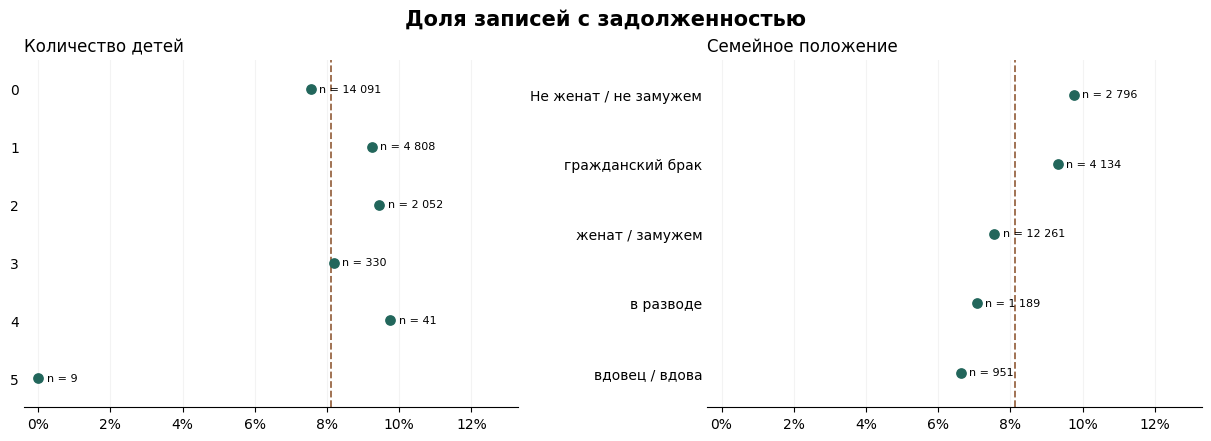

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharex=True, constrained_layout=True)
panel_titles = ['Количество детей', 'Семейное положение']
for ax, table, title in zip(axes, [children_table, family_table], panel_titles):
    y = list(range(len(table)))
    ax.axvline(overall_rate, linestyle='--', linewidth=1.3, color='#986745', zorder=1)
    ax.scatter(table['Доля, %'], y, color='#22665b', s=45, zorder=3)
    for pos, (_, row) in enumerate(table.iterrows()):
        n = f"{row['Записей']:,.0f}".replace(',', ' ')
        ax.annotate(f'n = {n}', (row['Доля, %'], pos), xytext=(6, 0),
                    textcoords='offset points', va='center', fontsize=8)
    ax.set_yticks(y, [str(x) for x in table.index])
    ax.set_ylim(len(table)-0.5, -0.5)
    ax.set_xlim(-0.4, 13.3)
    ax.set_xticks([0, 2, 4, 6, 8, 10, 12])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.set_title(title, loc='left')
    ax.grid(axis='x', alpha=.15)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(axis='y', length=0)
fig.suptitle('Доля записей с задолженностью', fontsize=15, fontweight='bold')
plt.show()

### Задание 21. Как различается доля задолженности по доходу

Рядом с результатом для всех записей покажу долю только по клиентам, которые указали доход. Это позволяет проверить, зависит ли сравнение крупных групп от заполнения пропусков медианой.

In [22]:
income_order = list('EDCBA')
income_table = debt_summary(data, 'total_income_category').reindex(income_order)
known_income = data.loc[~income_missing.loc[data.index]]
known_table = debt_summary(known_income, 'total_income_category')
income_table.insert(0, 'Доход в месяц, ₽', ['0–30 000', '30 001–50 000', '50 001–200 000',
                                          '200 001–1 000 000', 'от 1 000 001'])
income_table['С известным доходом'] = known_table['Записей']
income_table['Доля при известном доходе, %'] = known_table['Доля, %']
display(income_table.rename_axis('Категория').round(2))

,"Доход в месяц, ₽",Записей,С задолженностью,"Доля, %",С известным доходом,"Доля при известном доходе, %"
Категория,,,,,,
E,0–30 000,22,2,9.09,22,9.09
D,30 001–50 000,349,21,6.02,349,6.02
C,50 001–200 000,15921,1353,8.50,13831,8.55
B,200 001–1 000 000,5014,354,7.06,5013,7.06
A,от 1 000 001,25,2,8.00,25,8.00


В двух самых больших группах результат различается. При доходе 50 001–200 000 ₽ (C) доля задолженности равна 8,50%, а при 200 001–1 000 000 ₽ (B) — 7,06%. Разница составляет 1,44 п. п. Если взять только записи с известным исходным доходом, получим соответственно 8,55% и 7,06%. Направление различия сохраняется.

По всем пяти диапазонам последовательного снижения доли с ростом дохода не видно. В крайних категориях E и A всего 22 и 25 записей. В каждой из них только два случая задолженности, поэтому ранжировать эти группы по столь близким долям ненадёжно.

### Задание 22. Как связаны цель кредита и задолженность

In [23]:
purpose_table = debt_summary(data, 'purpose_category').sort_values('Доля, %', ascending=False)
display(purpose_table.rename_axis('Цель кредита').round(2))

,Записей,С задолженностью,"Доля, %"
Цель кредита,,,
операции с автомобилем,4279,400,9.35
получение образования,3988,369,9.25
проведение свадьбы,2313,183,7.91
операции с недвижимостью,10751,780,7.26


Чаще всего задолженность встречалась при операциях с автомобилем (9,35%) и получении образования (9,25%). При проведении свадьбы доля равна 7,91%, при операциях с недвижимостью — 7,26%. Разрыв между автомобилем и недвижимостью — около 2,09 п. п. У недвижимости больше всего записей, поэтому именно здесь больше всего случаев в абсолютном выражении (780), несмотря на самую низкую долю.

### Задание 23. Откуда могли появиться пропуски

В 2 174 исходных записях, или примерно 10,1%, одновременно отсутствуют доход и стаж. Записей, где пропущено лишь одно из этих двух полей, нет. Такое совпадение могло появиться, если часть анкет заполняли по сокращённой форме, клиент пропускал целиком раздел о работе или данные из этого раздела не переносились при выгрузке. Различить эти причины помогли бы версия анкеты и журнал загрузки.

### Задание 24. Почему для заполнения подходит медиана

In [24]:
display(observed_income_stats.rename(index={'median':'Медиана', 'mean':'Среднее', 'max':'Максимум'})
        .rename('Доход до заполнения, ₽').round(0).astype(int))

Медиана      145018
Среднее      167422
Максимум    2265604
Name: Доход до заполнения, ₽, dtype: int64

Среди исходных записей с известным доходом медиана составляет примерно 145 тыс. ₽, среднее — 167 тыс. ₽, а максимум превышает 2,26 млн ₽. Несколько больших доходов тянут среднее вверх. Медиану определяет положение наблюдений в упорядоченном ряду, поэтому она устойчивее к таким крайним значениям. Расчёт внутри типа занятости дополнительно учитывает, что у пенсионеров и сотрудников разные типичные доходы.

У замены есть цена. Многие строки получают одно и то же значение, разброс уменьшается, а в малочисленных группах сама медиана может держаться всего на одном наблюдении. Восстановленный доход остаётся оценкой. Именно поэтому выше я отдельно показал результат по анкетам с указанным доходом.

<a id="conclusion"></a>
## Шаг 4. Вывод для кредитного отдела

В 1 732 из 21 331 очищенных записей у клиента была задолженность — **8,12%**. В этой выборке она встречалась чаще у заёмщиков с детьми (9,24% против 7,54% без детей). Среди крупных групп по семейному положению доля ниже у состоящих в зарегистрированном браке (7,56%), чем у живущих в гражданском браке (9,31%) и у неженатых или незамужних (9,76%).

Доход и цель кредита тоже связаны с различиями в долях. Категория B показывает меньшую долю задолженности, чем C, в том числе среди анкет с известным доходом. На кредиты для автомобилей и образования приходится примерно девять случаев на сто записей, для операций с недвижимостью — около семи.

Эти сравнения описывают историю групп. Для оценки того, помогают ли признаки прогнозировать задолженность, нужна отдельная проверка на новых кредитах с учётом дохода, цели и других различий между клиентами. Особой осторожности требуют редкие группы и стаж с сомнительными единицами измерения.